# 02 · Mapas e animações

Visualizações geográficas e temporais dos indicadores do WPP2024:

1. **Mapas-múndi** da fecundidade em quatro anos e da variação entre 1950 e 2024.
2. **Animações (GIF)** da fecundidade no mapa, de 1950 a 2100, e da transição demográfica (fecundidade × expectativa de vida), com países coloridos por região.

Os GIFs são salvos em `figures/`, para uso em apresentações.

**Requisitos:** os mapas usam a malha `world-110m`, carregada pela internet. Na primeira execução é preciso ter conexão.

**Limitação:** a malha de 110 m não tem os países pequenos (ilhas do Pacífico e do Caribe, Santa Sé). Eles aparecem em cinza, sem valor.

In [21]:
import sys
from pathlib import Path

# permite importar src/ a partir de notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import io

import altair as alt
import numpy as np
import pandas as pd
import vl_convert as vlc
from IPython.display import Image, display
from PIL import Image as PILImage
from vega_datasets import data

from src.dados import carregar_medium, carregar_outras_variantes, paises

RAIZ = Path.cwd().parent
PASTA_FIG = RAIZ / "figures"
PASTA_FIG.mkdir(exist_ok=True)

medium = carregar_medium()
outras = carregar_outras_variantes()
paises_medium = paises(medium)

alt.data_transformers.disable_max_rows()

MALHA = alt.topo_feature(data.world_110m.url, "countries")

# Escala sequencial de uma só cor: mais fecundidade, tom mais escuro
ESCALA_TFR = alt.Scale(domain=[1, 3, 6], range=["#e8f1fc", "#6fa6e8", "#0b3a7a"], clamp=True)
# Escala divergente: queda em azul, aumento em laranja, zero em cinza-claro
ESCALA_VARIACAO = alt.Scale(domain=[-4, 0, 4], range=["#2a78d6", "#fcfcfb", "#eb6834"], clamp=True)
CINZA_SEM_DADO = "#d9d9d9"

def mapa(dados, coluna, titulo, escala, legenda, largura=680, altura=340, formato=".2f"):
    """Coropleta mundial: `dados` tem LocID, Location e a coluna a colorir."""
    return (
        alt.Chart(MALHA)
        .mark_geoshape(stroke="white", strokeWidth=0.4)
        .transform_lookup(lookup="id", from_=alt.LookupData(dados, "LocID", [coluna, "Location"]))
        .encode(
            color=alt.condition(
                f"isValid(datum.{coluna})",
                alt.Color(f"{coluna}:Q", scale=escala, legend=alt.Legend(title=legenda)),
                alt.value(CINZA_SEM_DADO),
            ),
            tooltip=[alt.Tooltip("Location:N", title="País"), alt.Tooltip(f"{coluna}:Q", title=legenda, format=formato)],
        )
        .project(type="equalEarth")
        .properties(title=titulo, width=largura, height=altura)
    )

def dados_ano(ano, coluna):
    return paises_medium[paises_medium["Time"] == ano][["LocID", "Location", coluna]]

## 1. Fecundidade no mapa-múndi, em 2024

Mapa de um ano. Cada país aparece com a cor da sua taxa de fecundidade total. Passe o cursor sobre um país para ver o valor.

In [22]:
mapa(dados_ano(2024, "TFR"), "TFR", "Taxa de fecundidade total em 2024", ESCALA_TFR, "TFR (filhos por mulher)")

alt.Chart(...)

## 2. Quatro momentos da transição

Os mapas usam a mesma escala de cor, para que a comparação entre anos seja direta. Em 1950, a maior parte do mundo estava no tom mais escuro. Em 2024, o escuro ficou restrito a poucos países.

In [23]:
def painel(anos, largura=420, altura=240):
    mapas = [
        mapa(dados_ano(ano, "TFR"), "TFR", str(ano), ESCALA_TFR, "TFR", largura, altura)
        for ano in anos
    ]
    return alt.vconcat(
        alt.hconcat(mapas[0], mapas[1]),
        alt.hconcat(mapas[2], mapas[3]),
    ).resolve_scale(color="shared")

painel([1950, 1980, 2010, 2024])

alt.VConcatChart(...)

## 3. Variação da fecundidade entre 1950 e 2024

Diferença de TFR entre os dois anos, por país. Azul é queda; laranja, aumento. Como a escala é divergente, o cinza-claro marca países sem variação.

In [24]:
var = (
    paises_medium[paises_medium["Time"] == 2024][["LocID", "Location", "TFR"]]
    .merge(paises_medium[paises_medium["Time"] == 1950][["LocID", "TFR"]], on="LocID", suffixes=("_2024", "_1950"))
)
var["variacao"] = var["TFR_2024"] - var["TFR_1950"]

alt.Chart(MALHA).mark_geoshape(stroke="white", strokeWidth=0.4).transform_lookup(
    lookup="id", from_=alt.LookupData(var, "LocID", ["variacao", "Location", "TFR_1950", "TFR_2024"])
).encode(
    color=alt.condition(
        "isValid(datum.variacao)",
        alt.Color("variacao:Q", scale=ESCALA_VARIACAO, legend=alt.Legend(title="Variação do TFR")),
        alt.value(CINZA_SEM_DADO),
    ),
    tooltip=[
        alt.Tooltip("Location:N", title="País"),
        alt.Tooltip("TFR_1950:Q", title="TFR 1950", format=".2f"),
        alt.Tooltip("TFR_2024:Q", title="TFR 2024", format=".2f"),
        alt.Tooltip("variacao:Q", title="Variação", format="+.2f"),
    ],
).project(type="equalEarth").properties(title="Variação do TFR, 1950 → 2024", width=680, height=340)

alt.Chart(...)

## 4. Animação: fecundidade no mapa, 1950–2100

Um quadro a cada cinco anos. Os quadros são desenhados com Altair, convertidos em imagem e unidos em um GIF. O GIF não é interativo, mas funciona em qualquer apresentação, sem internet.

A projeção começa em 2024; a faixa de cinco anos é suficiente para acompanhar a tendência sem produzir um arquivo grande.

Quadros: 31 | tamanho: 0.72 MB


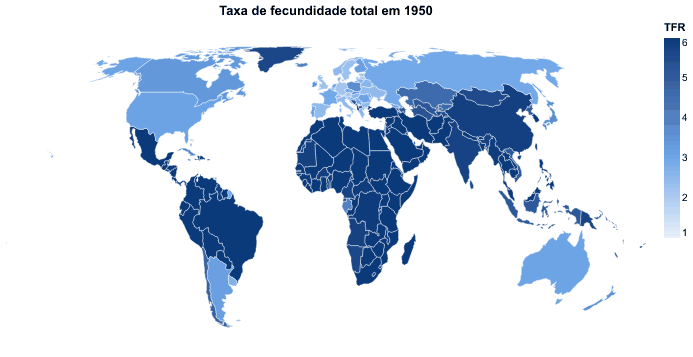

In [25]:
def _centralizar(imagem, largura, altura):
    tela = PILImage.new("RGB", (largura, altura), "white")
    tela.paste(imagem, (0, 0))
    return tela

def salvar_gif(anos, funcao_quadro, caminho, duracao_ms=450):
    quadros = []
    for ano in anos:
        png = vlc.vegalite_to_png(funcao_quadro(ano).to_dict(), scale=1)
        imagem = PILImage.open(io.BytesIO(png)).convert("RGBA")
        fundo = PILImage.new("RGBA", imagem.size, "white")
        fundo.alpha_composite(imagem)
        quadros.append(fundo.convert("RGB"))

    # Todos os quadros com o mesmo tamanho: o maior, com fundo branco
    largura = max(q.width for q in quadros)
    altura = max(q.height for q in quadros)
    quadros = [_centralizar(q, largura, altura) for q in quadros]
    quadros = [q.convert("P", palette=PILImage.ADAPTIVE, colors=128) for q in quadros]
    quadros[0].save(
        caminho,
        save_all=True,
        append_images=quadros[1:],
        duration=duracao_ms,
        loop=0,
        optimize=True,
    )
    return caminho

def quadro_tfr(ano):
    return mapa(dados_ano(ano, "TFR"), "TFR", f"Taxa de fecundidade total em {ano}", ESCALA_TFR, "TFR", 640, 330)

ANOS_MAPA = list(range(1950, 2101, 5))
gif_mapa = salvar_gif(ANOS_MAPA, quadro_tfr, PASTA_FIG / "tfr_mapa_1950_2100.gif")
print("Quadros:", len(ANOS_MAPA), "| tamanho:", round(gif_mapa.stat().st_size / 1e6, 2), "MB")
display(Image(filename=str(gif_mapa)))

## 5. Animação: transição demográfica por região

Cada ponto é um país, na posição da fecundidade e da expectativa de vida daquele ano. Os países migram do canto superior esquerdo (alta fecundidade e baixa expectativa de vida) para o canto inferior direito, em direção ao canto de baixa fecundidade e alta expectativa de vida. A cor indica a região.

Quadros: 31 | tamanho: 0.43 MB


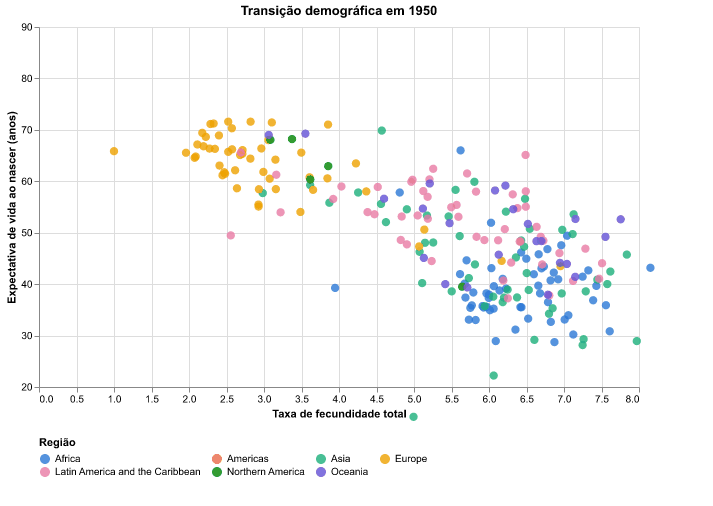

In [26]:
geo = medium[medium["LocTypeName"] == "Geographic region"][["LocID", "Location"]].drop_duplicates()
sub = medium[medium["LocTypeName"] == "Subregion"][["LocID", "ParentID"]].drop_duplicates()
nome_geo = dict(zip(geo["LocID"], geo["Location"]))
sub_para_regiao = {int(l): nome_geo.get(int(p)) for l, p in zip(sub["LocID"], sub["ParentID"])}
sub_para_regiao[918] = "Northern America"  # código usado como pai pelos países da América do Norte

REGIOES = sorted(geo["Location"].unique())
CORES_REGIOES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
escala_regiao = alt.Scale(domain=REGIOES, range=CORES_REGIOES)

base_regiao = paises_medium.copy()
base_regiao["regiao"] = base_regiao["ParentID"].map(
    lambda p: sub_para_regiao.get(int(p), nome_geo.get(int(p))) if pd.notna(p) else None
)

def quadro_dispersao(ano):
    d = base_regiao[base_regiao["Time"] == ano].dropna(subset=["TFR", "LEx"])
    return (
        alt.Chart(d)
        .mark_circle(size=70, opacity=0.8)
        .encode(
            x=alt.X("TFR:Q", title="Taxa de fecundidade total", scale=alt.Scale(domain=[0, 8])),
            y=alt.Y("LEx:Q", title="Expectativa de vida ao nascer (anos)", scale=alt.Scale(domain=[20, 90])),
            color=alt.Color("regiao:N", scale=escala_regiao, legend=alt.Legend(title="Região", orient="bottom", columns=4)),
            tooltip=["Location:N", alt.Tooltip("TFR:Q", format=".2f"), alt.Tooltip("LEx:Q", format=".1f")],
        )
        .properties(title=f"Transição demográfica em {ano}", width=600, height=360)
    )

gif_dispersao = salvar_gif(ANOS_MAPA, quadro_dispersao, PASTA_FIG / "transicao_dispersao_1950_2100.gif")
print("Quadros:", len(ANOS_MAPA), "| tamanho:", round(gif_dispersao.stat().st_size / 1e6, 2), "MB")
display(Image(filename=str(gif_dispersao)))

## 6. Crescimento da população por região

Cada país entra em uma única região, então a soma não conta ninguém duas vezes. O GIF mostra a população de cada região ano a ano; a linha de cada quadro indica se o ano é estimado ou projetado.

Quadros: 31 | tamanho: 0.07 MB


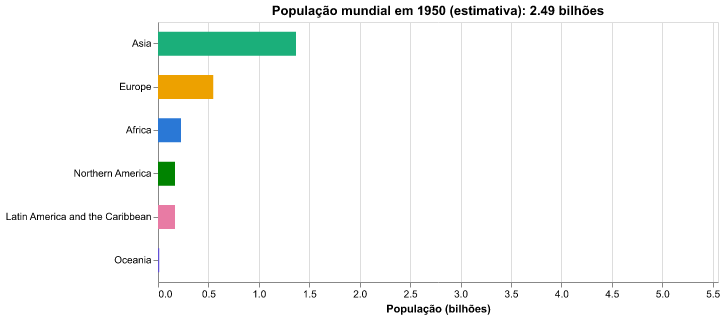

In [27]:
pop_regiao = (
    base_regiao.dropna(subset=["regiao"])
    .groupby(["Time", "regiao"], as_index=False)["TPopulation1July"].sum()
)
pop_regiao["bilhoes"] = pop_regiao["TPopulation1July"] / 1_000_000
LIMITE_X = pop_regiao["bilhoes"].max() * 1.05

def quadro_populacao(ano):
    d = pop_regiao[pop_regiao["Time"] == ano]
    total = d["bilhoes"].sum()
    situacao = "estimativa" if ano <= 2023 else "projeção"
    return (
        alt.Chart(d)
        .mark_bar(size=24)
        .encode(
            y=alt.Y("regiao:N", sort="-x", title=None),
            x=alt.X("bilhoes:Q", title="População (bilhões)", scale=alt.Scale(domain=[0, LIMITE_X])),
            color=alt.Color("regiao:N", scale=escala_regiao, legend=None),
            tooltip=["regiao:N", alt.Tooltip("bilhoes:Q", title="bilhões", format=".2f")],
        )
        .properties(
            title=f"População mundial em {ano} ({situacao}): {total:.2f} bilhões",
            width=560,
            height=260,
        )
    )

gif_populacao = salvar_gif(ANOS_MAPA, quadro_populacao, PASTA_FIG / "populacao_regioes_1950_2100.gif", duracao_ms=400)
print("Quadros:", len(ANOS_MAPA), "| tamanho:", round(gif_populacao.stat().st_size / 1e6, 2), "MB")
display(Image(filename=str(gif_populacao)))

## 7. Distribuição da população no mundo, com controle de ano

Esta visualização é **interativa**: arraste o controle deslizante para escolher o ano (1950 a 2100). O mapa colore cada país pela população, em escala logarítmica, e o gráfico ao lado mostra os 15 países mais populosos naquele ano.

Como depende do controle, não aparece como GIF. Para abrir no navegador, salve o notebook como HTML (`Arquivo › Exportar › HTML`) ou use `chart.save("populacao.html")`.

In [28]:
pop_pais = paises_medium[["LocID", "Location", "Time", "TPopulation1July"]].copy()
pop_pais["pop_milhoes"] = pop_pais["TPopulation1July"] / 1000
pop_pais["chave"] = pop_pais["LocID"].astype(str) + "_" + pop_pais["Time"].astype(str)

ano = alt.param(name="ano", value=2024, bind=alt.binding_range(min=1950, max=2100, step=1, name="Ano: "))

mapa_populacao = (
    alt.Chart(MALHA)
    .mark_geoshape(stroke="white", strokeWidth=0.3)
    .transform_calculate(chave="toString(datum.id) + '_' + toString(ano)")
    .transform_lookup(
        lookup="chave",
        from_=alt.LookupData(pop_pais, "chave", ["pop_milhoes", "Location"]),
    )
    .encode(
        color=alt.condition(
            "isValid(datum.pop_milhoes)",
            alt.Color(
                "pop_milhoes:Q",
                scale=alt.Scale(type="log", scheme="blues", domain=[0.01, 1500]),
                legend=alt.Legend(title="População (milhões, escala log)"),
            ),
            alt.value(CINZA_SEM_DADO),
        ),
        tooltip=[alt.Tooltip("Location:N", title="País"), alt.Tooltip("pop_milhoes:Q", title="milhões", format=",.2f")],
    )
    .project(type="equalEarth")
    .properties(width=620, height=320)
)

top_paises = (
    alt.Chart(pop_pais)
    .transform_filter("datum.Time == ano")
    .transform_window(rank="rank()", sort=[alt.SortField("TPopulation1July", order="descending")])
    .transform_filter("datum.rank <= 15")
    .mark_bar(size=14, color="#2a78d6")
    .encode(
        y=alt.Y("Location:N", sort="-x", title=None),
        x=alt.X("pop_milhoes:Q", title="População (milhões)"),
        tooltip=[alt.Tooltip("Location:N", title="País"), alt.Tooltip("pop_milhoes:Q", title="milhões", format=",.1f")],
    )
    .properties(width=320, height=320)
)

alt.hconcat(mapa_populacao, top_paises).add_params(ano)

alt.HConcatChart(...)

## 8. Ano em que a fecundidade cruza a reposição

A reposição é de cerca de 2,1 filhos por mulher. O mapa mostra, para cada país, o **primeiro ano** em que a fecundidade ficou abaixo desse valor. Países em cinza não chegam a 2,1 até 2100.

In [29]:
abaixo = paises_medium[(paises_medium["TFR"] < 2.1) & (paises_medium["Time"] <= 2100)]
reposicao = (
    abaixo.groupby(["LocID", "Location"], as_index=False)["Time"].min()
    .rename(columns={"Time": "ano_reposicao"})
)
print("Países que chegam à reposição até 2100:", len(reposicao), "de", paises_medium["LocID"].nunique())

mapa(reposicao, "ano_reposicao", "Primeiro ano com fecundidade abaixo de 2,1",
     alt.Scale(scheme="viridis"), "Ano", formato="d")

Países que chegam à reposição até 2100: 224 de 237


alt.Chart(...)

## 9. Ano do pico populacional (projeções)

Para cada país, o ano em que a população atinge o máximo entre 1950 e 2100. Quem ainda cresce em 2100 aparece com o pico em 2100, e o gráfico de barras separa esse caso.

In [30]:
idx_pico = paises_medium[paises_medium["Time"] <= 2100].groupby("LocID")["TPopulation1July"].idxmax()
pico = paises_medium.loc[idx_pico, ["LocID", "Location", "Time"]].rename(columns={"Time": "ano_pico"})

faixas = pd.cut(
    pico["ano_pico"],
    bins=[1949, 2023, 2050, 2099, 2100],
    labels=["até 2023", "2024–2050", "2051–2099", "2100 (ainda cresce)"],
)
print(faixas.value_counts().sort_index().rename("países"))

mapa(pico, "ano_pico", "Ano do pico populacional", alt.Scale(scheme="viridis"), "Ano do pico", formato="d")

ano_pico
até 2023               60
2024–2050              42
2051–2099              60
2100 (ainda cresce)    75
Name: países, dtype: int64


alt.Chart(...)

## 10. Trajetória da fecundidade por país, com seleção

Escolha um país no menu. O país aparece em destaque, sobre as demais trajetórias em cinza, e a mediana entre os países aparece como linha tracejada.

In [31]:
nomes_paises = sorted(paises_medium["Location"].unique())
pais = alt.param(name="pais", value="Brazil", bind=alt.binding_select(options=nomes_paises, name="País: "))

serie_tfr = paises_medium[["LocID", "Location", "Time", "TFR"]].dropna()
mediana_tfr = serie_tfr.groupby("Time", as_index=False)["TFR"].median()

base_linhas = alt.Chart(serie_tfr).encode(
    x=alt.X("Time:Q", title="Ano", axis=alt.Axis(format="d")),
    y=alt.Y("TFR:Q", title="Taxa de fecundidade total"),
    detail="Location:N",
)
fundo = base_linhas.mark_line(strokeWidth=0.8, opacity=0.2, color="#8a8a8a")
destaque = base_linhas.transform_filter("datum.Location == pais").mark_line(strokeWidth=3, color="#2a78d6")
mediana = alt.Chart(mediana_tfr).mark_line(strokeWidth=2, strokeDash=[5, 4], color="#0b0b0b").encode(
    x="Time:Q", y="TFR:Q"
)
alt.layer(fundo, destaque, mediana).add_params(pais).properties(width=640, height=360)

alt.LayerChart(...)

## 11. Leque de incerteza por região

Para cada região, a faixa de 95% das projeções de população e a mediana (variante *Median PI*). **Aproximação:** a soma de limites de intervalo não é o limite do total. A faixa abaixo soma os limites de cada país, o que costuma subestimar a incerteza real da região, porque os erros de países diferentes se compensam.

In [32]:
VARIANTES_PI = ["Lower 95 PI", "Median PI", "Upper 95 PI"]
pi_paises = outras[
    outras["Variant"].isin(VARIANTES_PI)
    & (outras["LocTypeName"] == "Country/Area")
    & outras["Time"].between(2024, 2100)
]
regiao_por_pais = base_regiao.dropna(subset=["regiao"])[["LocID", "regiao"]].drop_duplicates("LocID")

pi_regiao = (
    pi_paises.merge(regiao_por_pais, on="LocID")
    .groupby(["regiao", "Time", "Variant"], as_index=False)["TPopulation1July"].sum()
)
pi_regiao["bilhoes"] = pi_regiao["TPopulation1July"] / 1_000_000
pi_larga = (
    pi_regiao.pivot_table(index=["regiao", "Time"], columns="Variant", values="bilhoes")
    .reset_index()
    .rename(columns={"Lower 95 PI": "inferior", "Median PI": "mediana", "Upper 95 PI": "superior"})
)

banda_pi = alt.Chart(pi_larga).mark_area(opacity=0.3).encode(
    x=alt.X("Time:Q", title="Ano", axis=alt.Axis(format="d")),
    y=alt.Y("inferior:Q", title="População (bilhões)"),
    y2="superior:Q",
    color=alt.Color("regiao:N", scale=escala_regiao, legend=None),
)
linha_pi = alt.Chart(pi_larga).mark_line(strokeWidth=2).encode(
    x="Time:Q",
    y="mediana:Q",
    color=alt.Color("regiao:N", scale=escala_regiao, legend=None),
)
alt.layer(banda_pi, linha_pi).properties(width=260, height=200).facet(
    facet=alt.Facet("regiao:N", title=None), columns=3
).resolve_scale(y="independent")

alt.FacetChart(...)

## 12. Crescimento natural em 2024

Diferença entre nascimentos e óbitos, por mil habitantes. Azul indica crescimento natural positivo; laranja, população que encolhe por causa da mortalidade.

In [33]:
ESCALA_CRESCIMENTO = alt.Scale(domain=[-10, 0, 10], range=["#2a78d6", "#fcfcfb", "#eb6834"], clamp=True)
mapa(dados_ano(2024, "NatChangeRT"), "NatChangeRT", "Crescimento natural em 2024",
     ESCALA_CRESCIMENTO, "Por mil habitantes", formato=".1f")

alt.Chart(...)

## 13. Fecundidade dos 40 países mais populosos ao longo do tempo

Cada linha é um país; cada coluna, um ano (de 5 em 5 anos). Os países estão ordenados pela fecundidade em 2024, do menor para o maior. O padrão de queda aparece como uma mudança de cor da esquerda para a direita.

In [34]:
top40 = paises_medium[paises_medium["Time"] == 2024].nlargest(40, "TPopulation1July")["Location"].tolist()
tfr_2024 = paises_medium[paises_medium["Time"] == 2024].set_index("Location")["TFR"]
ordem_paises = tfr_2024.loc[top40].sort_values().index.tolist()

grade = paises_medium[
    paises_medium["Location"].isin(top40) & paises_medium["Time"].between(1950, 2100) & (paises_medium["Time"] % 5 == 0)
][["Location", "Time", "TFR"]]

alt.Chart(grade).mark_rect().encode(
    x=alt.X("Time:O", title="Ano", axis=alt.Axis(labelAngle=-90, labelOverlap=True)),
    y=alt.Y("Location:N", sort=ordem_paises, title=None),
    color=alt.Color("TFR:Q", scale=ESCALA_TFR, legend=alt.Legend(title="TFR")),
    tooltip=["Location:N", "Time:O", alt.Tooltip("TFR:Q", format=".2f")],
).properties(width=640, height=520)

alt.Chart(...)

## 14. Distribuição da fecundidade por época (ridgeline)

Cada faixa é a distribuição da fecundidade entre os países em um ano. A faixa se move para a esquerda e se estreita ao longo do tempo: os países ficam mais parecidos entre si.

In [35]:
EPOCAS = [1950, 1970, 1990, 2010, 2030, 2050, 2100]
dist = paises_medium[paises_medium["Time"].isin(EPOCAS)][["Location", "Time", "TFR"]].dropna()

ridgeline = (
    alt.Chart(dist)
    .transform_density("TFR", groupby=["Time"], as_=["TFR", "densidade"], extent=[0, 8], steps=60)
    .mark_area(orient="horizontal", opacity=0.8, color="#2a78d6", interpolate="monotone", line={"color": "#0b3a7a"})
    .encode(
        y=alt.Y("TFR:Q", title=None, scale=alt.Scale(domain=[0, 8])),
        x=alt.X("densidade:Q", axis=None),
    )
    .properties(width=420, height=55)
    .facet(row=alt.Row("Time:O", title=None, header=alt.Header(labelAngle=0)))
    .configure_facet(spacing=-8)
)
ridgeline

alt.FacetChart(...)

## Cuidados

- Os GIFs ficam em `figures/`. Se forem versionados, considere o tamanho antes do commit.
- Os quadros de 2025 em diante são **projeções**. Na apresentação, é bom marcar isso no título ou na legenda.
- Países pequenos somem no mapa de 110 m: vale dizer isso em qualquer slide com mapa.